# Turn rule and individuals

The rule the models learned, read from their teacher-forced predictions on the held-out fish (how the turn toward
the dots depends on the time since they appeared and on their range), and how far a simulated individual is from
the real ones. The heavy computations are cached in `output/missing_pieces/`; `uv run python -m twin.missing_pieces
<section>` redoes one (sections: refs, nearest, laws_draw).

In [1]:
import numpy as np
import pandas as pd
from twin import missing_pieces as P
pd.set_option("display.width", 200)

## The turn when the dots appear, and the step and interval (Figure fig:rule)
Real fish: the observed bout; M6 and F: the expected turn, step and interval on the same held-out bouts, at the same
matched geometry (moving dots, bearing 45-135 deg, 0-60 mm).

  log step: mean draw - expected +0.007, SD one draw 0.458 vs real 0.448
  log interval: mean draw - expected +0.002, SD one draw 0.538 vs real 0.561


  wrote figures/out/fig_rule_3panel.pdf


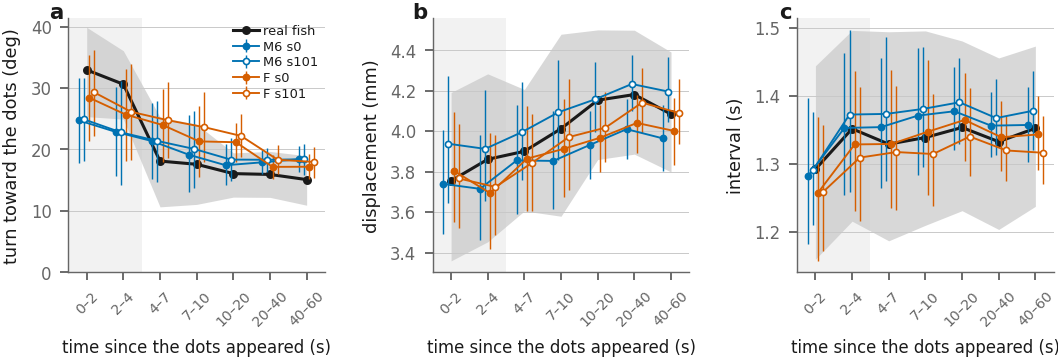


step by time bin ['0-2', '2-4', '4-7', '7-10', '10-20', '20-40', '40-60']
  real      3.754  3.861  3.901  4.012  4.153  4.181  4.084
  M6 s0     3.739  3.715  3.855  3.853  3.932  4.010  3.964
  M6 s101   3.938  3.913  3.995  4.094  4.157  4.233  4.196
  F s0      3.805  3.693  3.864  3.913  3.968  4.041  4.002
  F s101    3.766  3.724  3.843  3.971  4.017  4.141  4.090

interval by time bin ['0-2', '2-4', '4-7', '7-10', '10-20', '20-40', '40-60']
  real      1.292  1.351  1.329  1.338  1.353  1.332  1.352
  M6 s0     1.281  1.353  1.354  1.371  1.377  1.356  1.357
  M6 s101   1.290  1.372  1.373  1.381  1.390  1.367  1.378
  F s0      1.257  1.328  1.329  1.347  1.364  1.339  1.343
  F s101    1.258  1.309  1.317  1.314  1.340  1.319  1.316


In [2]:
from figures import fig_rule_kin
fig_rule_kin.main()

## Turn toward the dots by range (Figure fig:range-law, Table tab:range-law)
From 10 s into the block, bearing 45-135 deg; real fish with the 95 % interval over fish, models from their own
rollouts (* = outside the real interval).

== 2–8 moving dots
  real      0–10:  10.1 [  7.3,  13.3] n=15  10–20:  19.7 [ 14.3,  25.0] n=15  20–30:  24.8 [ 19.9,  29.8] n=15  30–45:  18.9 [ 12.8,  26.1] n=15  45–70:  11.7 [  5.8,  17.2] n=13
  M6 s0   0–10:  14.0 *  10–20:  18.6  20–30:  18.3 *  30–45:  18.0  45–70:  17.5 *   (* outside the real 95 % CI)
  M6 s101 0–10:  17.6 *  10–20:  20.8  20–30:  21.0  30–45:  19.1  45–70:  18.4 *   (* outside the real 95 % CI)
  D4 s0   0–10:  10.1  10–20:  21.8  20–30:  23.0  30–45:  16.3  45–70:   9.7   (* outside the real 95 % CI)
  D4 s101 0–10:  11.8  10–20:  21.5  20–30:  21.8  30–45:  15.2  45–70:   9.7   (* outside the real 95 % CI)
  F s0   0–10:  11.9  10–20:  22.8  20–30:  23.9  30–45:  13.4  45–70:  12.7   (* outside the real 95 % CI)
  F s101 0–10:  13.8 *  10–20:  22.5  20–30:  24.5  30–45:  16.6  45–70:  10.8   (* outside the real 95 % CI)
== 1 moving dot
  real      0–10:  -6.9 [-13.8,   0.1] n=14  10–20:  19.5 [ 13.9,  25.5] n=15  20–30:  11.7 [  4.8,  18.4] n=15  30–45:  

  wrote figures/out/fig_range_law.pdf


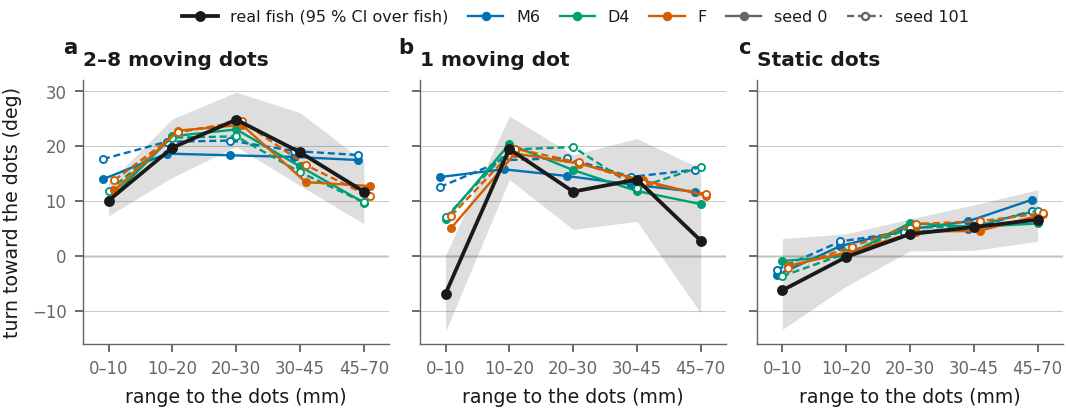

In [3]:
from figures import fig_range_law
fig_range_law.main()

## Simulated fish lie inside the cloud of real individuals (Table tab:nrn)
Distance of each individual to its nearest real fish: the pairwise classifier AUC to the closest real fish.
Inside: simulated individuals closer to their nearest real fish than the median real fish is to its own.

In [4]:
N = P.load("nearest")


def row(v):
    v = np.asarray(v, float)
    return dict(n=len(v), mean=round(v.mean(), 3), se=round(v.std(ddof=1) / np.sqrt(len(v)), 3),
                median=round(np.median(v), 3), p10=round(np.quantile(v, 0.1), 3), p90=round(np.quantile(v, 0.9), 3))


real = N["M6 s0"]["per"]["nearest_real"]
rows = {"real fish": row(real)}
for lab, v in N.items():
    rows[lab] = {**row(v["nn_sampled"]), "inside": int((v["nn_sampled"] < np.median(real)).sum())}
pd.DataFrame(rows).T

,n,mean,se,median,p10,p90,inside
real fish,15.0,0.838,0.019,0.843,0.756,0.942,NaN
M6 s0,120.0,0.857,0.008,0.857,0.739,0.978,54.0
M6 s101,120.0,0.864,0.006,0.859,0.787,0.964,46.0
F s0,120.0,0.864,0.008,0.868,0.747,0.988,46.0
F s101,120.0,0.832,0.009,0.831,0.705,0.959,66.0


## The classifier's floor: real against real
Each fish's real windows split into random halves (five splits): the "Real" row of the model tables.

In [5]:
P.load("refs")["table"].loc[["real vs real (random halves of each fish)"]].round(3)

,all features,all features se,no radial,no radial se,three heads,three heads se
generator,,,,,,
real vs real (random halves of each fish),0.499,0.007,0.502,0.007,0.503,0.012
